In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
from kalman.helpers import rainbow

Note: you may need to restart the kernel to use updated packages.


# Sensor Fusion with a Kalman Filter

Several sensors watch the same moving target. They report at different rates and each has its own
noise level. The Kalman filter combines them into one estimate, giving each sensor a weight
proportional to $1/\sigma^2$, where $\sigma$ is that sensor's noise standard deviation. A precise
sensor counts for much more than a noisy one.

Different rates need no special handling. When a sensor has no reading at a time step, its entry
in the measurement vector is `NaN` and the filter skips it.

`SensorFusionModel` tracks a target moving along a line at roughly constant velocity. The state is
$\mathbf{x}=[\,p,\ v\,]$: position $p$ in m and velocity $v$ in m/s. Each sensor is described by a
`SensorSpec`: what it measures, its noise and its rate.

The notebook covers two cases:

- **Redundant sensors** measure the same quantity (three position sensors).
- **Complementary sensors** measure different quantities (a position sensor and a velocity sensor).

## Step 1 — Set Up Three Redundant Position Sensors

Three sensors measure the position of the target, with values typical of a car:

| sensor | noise $\sigma$ | rate |
|---|---|---|
| GPS | 3 m | 10 Hz |
| Radar | 0.3 m | 25 Hz |
| Lidar | 0.05 m | 10 Hz |

Each sensor adds one row to the measurement matrix $\mathbf{H}$ and one variance to the diagonal
of $\mathbf{R}=\mathrm{diag}(\sigma_i^2)$.

The argument `uncertainty` is the noise standard deviation $\sigma$ of a sensor, in m. The
argument `process_uncertainty` says how much the target's velocity may wander: it is the standard
deviation of a random acceleration, here 2 m/s² (per $\sqrt{\text{Hz}}$). It sets $\mathbf{Q}$.

In [2]:
from kalman.apps.fusion import SensorFusionModel, SensorSpec

fs = 50.0   # filter rate [Hz]
sensors = [
    SensorSpec("GPS",   "position", uncertainty=3.0,  rate=10),
    SensorSpec("Radar", "position", uncertainty=0.3,  rate=25),
    SensorSpec("Lidar", "position", uncertainty=0.05, rate=10),
]
model = SensorFusionModel("target", sensors, fs=fs, process_uncertainty=2.0)
model.initial_state([0.0, 8.0])          # start at p = 0 m, moving at 8 m/s
print(f"state dim n={model.n}  measurement dim m={model.m}  (one row per sensor)")

state dim n=2  measurement dim m=3  (one row per sensor)


## Step 2 — Build the Asynchronous Stream and Fuse

`make_measurements` samples each sensor at its own rate, adds its noise, and places the readings
on the 50 Hz grid of the filter. Steps without a reading hold `NaN`.

The top panel shows the raw readings and the fused estimate with its $\pm\sigma$ band. The bottom
panel compares the position uncertainty of the fused estimate with what each sensor would reach
alone.

measurement matrix: (400, 3)  NaN fraction per sensor: [0.8 0.5 0.8]


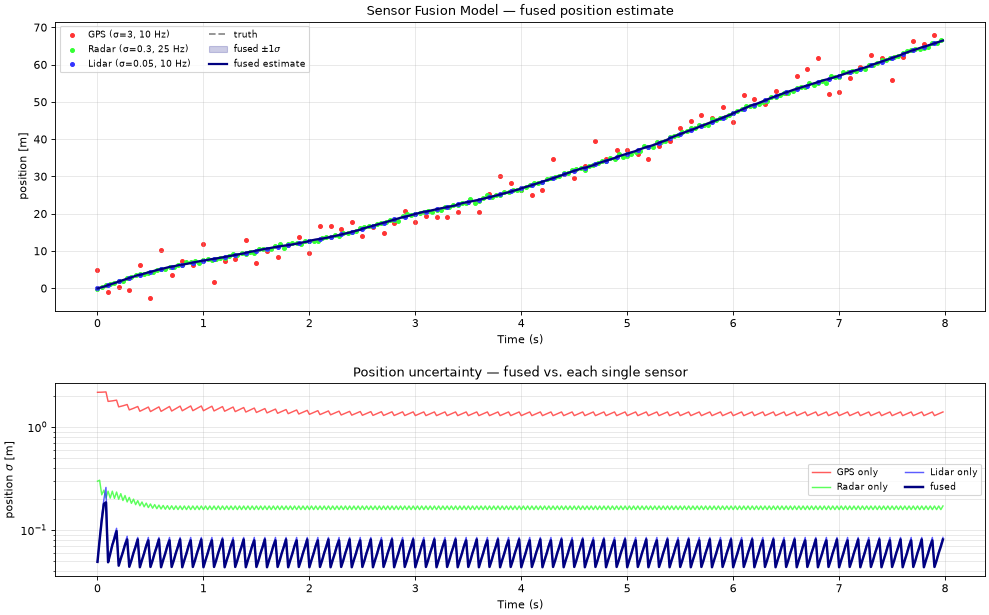

In [3]:
truth = model.sample(8.0)                       # true trajectory, 8 s
zk = model.make_measurements(truth, seed=1)     # one column per sensor, NaN where it has no reading
print("measurement matrix:", zk.shape, " NaN fraction per sensor:",
      np.round(np.isnan(zk).mean(axis=0), 2))

record = model.filter(zk)
model.plot(record, sample=truth, measurements=zk,
           meas=dict(alpha=1.0), colors=rainbow(len(model.sensors), l=0.6))
plt.show()

## Step 3 — Compare Fusion Against Each Single Sensor

To see what one sensor achieves alone, we filter again with the other columns set to `NaN`.
The table gives the final position uncertainty $\sigma$ and the root-mean-square error (RMSE)
against the true position, both in m.

The fused estimate is better than every single sensor, but only slightly better than the lidar.
With weights proportional to $1/\sigma^2$, the lidar counts 36 times more than the radar and
3600 times more than the GPS.

In [4]:
true_pos = truth.xk[:, 0]


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


print(f"{'sensor':<10}{'final sigma [m]':>16}{'RMSE [m]':>12}")
for i, sensor in enumerate(sensors):
    single_record = model.single_sensor_record(zk, i)
    single_sigma = np.sqrt(single_record.Pk[-1, 0, 0])
    single_rmse = rmse(single_record.xk[:, 0], true_pos)
    print(f"{sensor.name:<10}{single_sigma:>16.3f}{single_rmse:>12.3f}")

fused_sigma = np.sqrt(record.Pk[-1, 0, 0])
fused_rmse = rmse(record.xk[:, 0], true_pos)
print(f"{'FUSED':<10}{fused_sigma:>16.3f}{fused_rmse:>12.3f}")

sensor     final sigma [m]    RMSE [m]
GPS                  1.403       0.952
Radar                0.172       0.141
Lidar                0.085       0.062
FUSED                0.081       0.058


## Step 4 — Fuse Complementary Sensors: Position and Velocity

A car has a GPS that gives its position 5 times per second with 3 m of noise, and wheel odometry
(a count of wheel rotations) that gives its speed 50 times per second with 0.1 m/s of noise.

Neither is enough alone:

- GPS alone is noisy and slow.
- Odometry alone gives no position. Integrating the speed only says how far the car has moved, so
  the uncertainty on the starting point (3.2 m here) never shrinks.

Together, the odometry follows the motion between GPS fixes and the GPS removes the drift.

GPS only       final position sigma = 1.56 m
Odometry only  final position sigma = 3.16 m
fused          final position sigma = 0.47 m


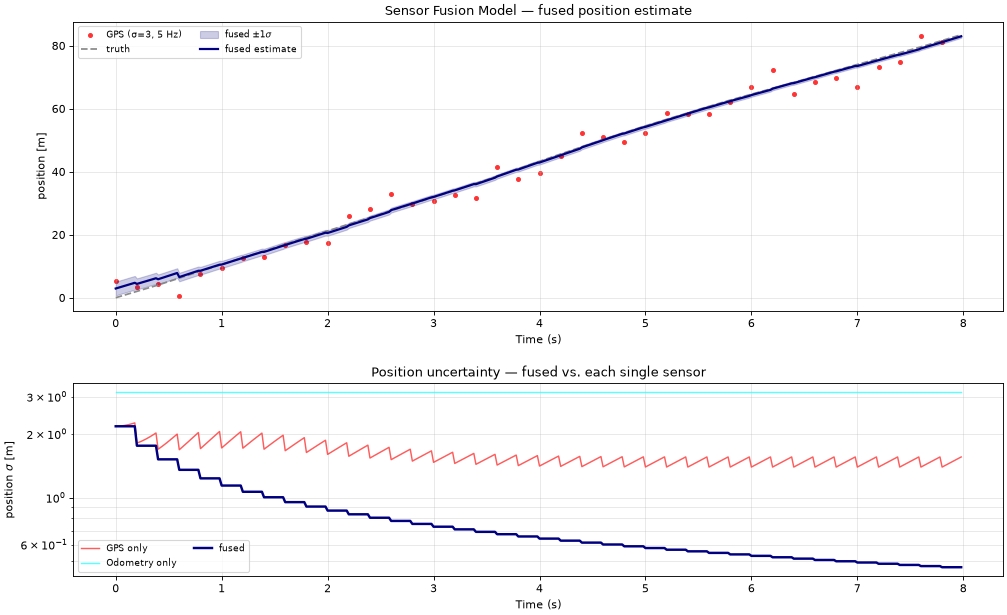

In [5]:
comp = SensorFusionModel("car", [
    SensorSpec("GPS",      "position", uncertainty=3.0, rate=5),    # slow, noisy position
    SensorSpec("Odometry", "velocity", uncertainty=0.1, rate=50),   # fast, precise velocity
], fs=50.0, process_uncertainty=1.0)
comp.initial_state([0.0, 10.0])

car_truth = comp.sample(8.0)
car_measurements = comp.make_measurements(car_truth, seed=3)
car_record = comp.filter(car_measurements)

for i, sensor in enumerate(comp.sensors):
    single = comp.single_sensor_record(car_measurements, i)
    print(f"{sensor.name + ' only':<14} final position sigma = {np.sqrt(single.Pk[-1, 0, 0]):.2f} m")
print(f"{'fused':<14} final position sigma = {np.sqrt(car_record.Pk[-1, 0, 0]):.2f} m")

comp.plot(car_record, sample=car_truth, measurements=car_measurements,
          meas=dict(alpha=1.0), colors=rainbow(len(comp.sensors), l=0.6))
plt.show()

## Step 5 — Why Fusion Works: Inverse-Variance Weighting

Take two readings $z_1$ and $z_2$ of the same position, made at the same time, with noise
$\sigma_1$ and $\sigma_2$. The best combination weights each reading by the inverse of its
variance:

$$\hat p = \frac{z_1/\sigma_1^2 + z_2/\sigma_2^2}{1/\sigma_1^2+1/\sigma_2^2},
\qquad
\sigma_{\text{fused}}^2 = \frac{1}{1/\sigma_1^2+1/\sigma_2^2}$$

The fused variance is smaller than either input variance, so adding a sensor never hurts. The
Kalman update does this at every step, for any number of sensors, and carries the result forward
in time.

In [6]:
sigma1, sigma2 = 3.0, 4.0   # [m]

inv_var1 = 1.0 / sigma1 ** 2
inv_var2 = 1.0 / sigma2 ** 2
total_inv_var = inv_var1 + inv_var2

fused_var = 1.0 / total_inv_var
fused_sigma = fused_var ** 0.5
print(f"sigma1 = {sigma1} m, sigma2 = {sigma2} m  ->  fused sigma = {fused_sigma:.1f} m")

weight1 = inv_var1 / total_inv_var
weight2 = inv_var2 / total_inv_var
print("inverse-variance weights:", np.round([weight1, weight2], 3))

sigma1 = 3.0 m, sigma2 = 4.0 m  ->  fused sigma = 2.4 m
inverse-variance weights: [0.64 0.36]


## Takeaways

- Sensor fusion is the Kalman measurement update with one row of $\mathbf{H}$ and one diagonal
  entry of $\mathbf{R}$ per sensor.
- Sensors with different rates need nothing special: a missing reading is a `NaN`, and the filter
  skips it.
- Each sensor is weighted by $1/\sigma^2$. Redundant sensors reduce the variance, and the most
  precise one dominates. Complementary sensors measure different parts of the state and together
  determine all of it.